# Classifying TikTok Videos Using Machine Learning 

## Introduction

The objective of this analysis is to build a classification machine learning model to predict whether a TikTok video presents a *claim* or an *opinion*. This automates the initial triage of user reports so human moderators can prioritize claims more efficiently. 

#### Ethical Considerations & Evaluation Metric 
* **False Negatives (Predicting an *opinion* when it is actually a *claim*):** 
    * A video containing a claim bypasses automated flagging and does not get prioritized for human review. This is the **worse error** because potentially harmful misinformation or policy-violating claims remain unmoderated. 
* **False Positives (Predicting a *claim* when it is actually an *opinion*):** 
    * An innocent opinion video gets routed to human moderators for review. While this slightly reduces workflow efficiency, it does not directly harm users since a human moderator makes the final decision. 
* **Primary Evaluation Metric:** 
    * Because minimizing **False Negatives** is the top priority, the model should be optimized using **Recall**  ($\frac{TP}{TP + FN}$) while monitoring **Precision** to ensure the model isn't simply labeling every video as a claim. 

### Imports & Data Loading

In [47]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

pd.set_option('display.max_columns', None)

In [48]:
DATA_PATH = Path("tiktok_dataset.csv")
tiktok_data = pd.read_csv(DATA_PATH)
df = tiktok_data.copy()

## EDA

### Initial Exploration

In [49]:
df.head()

,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19382 entries, 0 to 19381
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   #                         19382 non-null  int64  
 1   claim_status              19084 non-null  str    
 2   video_id                  19382 non-null  int64  
 3   video_duration_sec        19382 non-null  int64  
 4   video_transcription_text  19084 non-null  str    
 5   verified_status           19382 non-null  str    
 6   author_ban_status         19382 non-null  str    
 7   video_view_count          19084 non-null  float64
 8   video_like_count          19084 non-null  float64
 9   video_share_count         19084 non-null  float64
 10  video_download_count      19084 non-null  float64
 11  video_comment_count       19084 non-null  float64
dtypes: float64(5), int64(3), str(4)
memory usage: 1.8 MB


*Note*: 7 features contain 298 missing values, to be inspected. 

In [51]:
df.describe()

,#,video_id,video_duration_sec,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
count,19382.000000,1.938200e+04,19382.000000,19084.000000,19084.000000,19084.000000,19084.000000,19084.000000
mean,9691.500000,5.627454e+09,32.421732,254708.558688,84304.636030,16735.248323,1049.429627,349.312146
std,5595.245794,2.536440e+09,16.229967,322893.280814,133420.546814,32036.174350,2004.299894,799.638865
min,1.000000,1.234959e+09,5.000000,20.000000,0.000000,0.000000,0.000000,0.000000
25%,4846.250000,3.430417e+09,18.000000,4942.500000,810.750000,115.000000,7.000000,1.000000
50%,9691.500000,5.618664e+09,32.000000,9954.500000,3403.500000,717.000000,46.000000,9.000000
75%,14536.750000,7.843960e+09,47.000000,504327.000000,125020.000000,18222.000000,1156.250000,292.000000
max,19382.000000,9.999873e+09,60.000000,999817.000000,657830.000000,256130.000000,14994.000000,9599.000000


*Note*: Engagement metric means are significantly higher than medians. This is indicative of heavy right-skew; while tree-based models are robust to outliers and do not require outlier removal or feature scaling, this is still to be inspected. 

### Data Cleaning

#### Renaming Columns 

In [52]:
df.columns

Index(['#', 'claim_status', 'video_id', 'video_duration_sec',
       'video_transcription_text', 'verified_status', 'author_ban_status',
       'video_view_count', 'video_like_count', 'video_share_count',
       'video_download_count', 'video_comment_count'],
      dtype='str')

In [53]:
col_dict = {'video_id':'id', 
            'video_duration_sec':'duration', 
            'video_transcription_text':'text', 
            'author_ban_status':'ban_status', 
            'video_view_count':'views', 
            'video_like_count':'likes', 
            'video_share_count':'shares', 
            'video_download_count':'downloads', 
            'video_comment_count':'comments'}

df.rename(columns=col_dict, inplace=True)

In [54]:
df.head()

,#,claim_status,id,duration,text,verified_status,ban_status,views,likes,shares,downloads,comments
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


#### Missing & Duplicate Values Check

In [55]:
# Missing Values Check:
df.isna().sum()

#                    0
claim_status       298
id                   0
duration             0
text               298
verified_status      0
ban_status           0
views              298
likes              298
shares             298
downloads          298
comments           298
dtype: int64

In [56]:
# Missing Values Action: 
df.dropna(axis=0, inplace=True)
df.isna().sum()

#                  0
claim_status       0
id                 0
duration           0
text               0
verified_status    0
ban_status         0
views              0
likes              0
shares             0
downloads          0
comments           0
dtype: int64

In [57]:
# Duplicates Check:

df.duplicated().sum()

np.int64(0)

*Note*: None required. There are 0 duplicate rows.


### Feature-Specific Investigations

#### Class Balance

In [58]:
pd.DataFrame({
    'Count': df['claim_status'].value_counts(),
    'Percentage (%)': (df['claim_status'].value_counts(normalize=True) * 100).round(2)
})

,Count,Percentage (%)
claim_status,,
claim,9608,50.35
opinion,9476,49.65


* **Claims:** 9,608 (50.35%)
* **Opinions:** 9,476 (49.65%)
* The dataset is nearly perfectly balanced, so no resampling (e.g. SMOTE or undersampling) is needed. 

#### Engagement Metrics & Outlier Inspection

In [59]:
# Compare engagement distributions between claims and opinions
engagement_cols = ['views', 'likes', 'shares', 'downloads', 'comments']
df.groupby('claim_status')[engagement_cols].agg(['min', 'median', 'mean', 'max', 'std']).round(2)

views                                           likes  \
                 min    median       mean       max        std   min   
claim_status                                                           
claim         1049.0  501555.0  501029.45  999817.0  291349.24   0.0   
opinion         20.0    4953.0    4956.43    9998.0    2885.91   0.0   

                                                       shares           \
                median       mean       max        std    min   median   
claim_status                                                             
claim         123649.0  166373.33  657830.0  147623.37    0.0  17997.5   
opinion          823.0    1092.73    4375.0     964.10    0.0    121.0   

                                           downloads                   \
                  mean       max       std       min  median     mean   
claim_status                                                            
claim         33026.42  256130.0  38781.68       0.0  1139.5  2070.95   
opinion         217.15    1674.0    252.27       0.0     7.0    13.68   

                               comments                                  
                  max      std      min median    mean     max      std  
claim_status                                                             
claim         14994.0  2424.38      0.0  286.0  691.16  9599.0  1017.22  
opinion         101.0    16.20      0.0    1.0    2.70    32.0     4.09

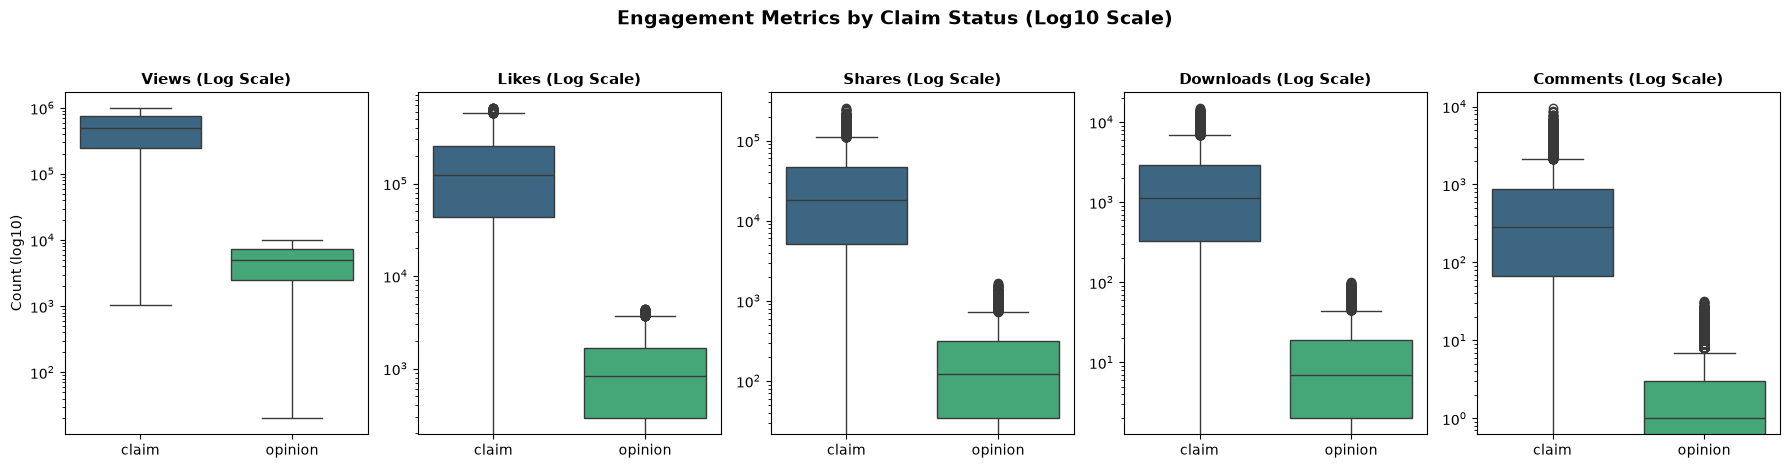

In [60]:
# Visualize engagement separation across claim_status on a log10 scale
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))

for idx, col in enumerate(engagement_cols):
    sns.boxplot(data=df, x='claim_status', y=col, palette='viridis', ax=axes[idx], hue='claim_status', legend=False)
    axes[idx].set_yscale('log')
    axes[idx].set_title(f'{col.capitalize()} (Log Scale)', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('Count (log10)' if idx == 0 else '')

fig.suptitle('Engagement Metrics by Claim Status (Log10 Scale)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show();

##### **Engagement Distribution & Outlier Insights**
* **Stark Class Separation:** Across all five engagement metrics, **claim** videos garner orders of magnitude more engagement than **opinion** videos. For example, claim videos have a mean of **`501,029.45` views** (median: `501,555.0`), whereas opinion videos have a mean of just **`4,956.43` views** (median: `4,953.0`).
* **Hard Ceiling on Opinions:** No opinion video in the entire dataset exceeds **`9,998` views**, **`4,375` likes**, **`1,674` shares**, **`101` downloads**, or **`32` comments**. Meanwhile, `99.0%` of claim videos (`9,512` out of `9,608`) exceed `10,000` views.
* **Modeling Implication:** While individual classes exhibit right-skewness, these high engagement values are genuine signal rather than data-entry errors. Because tree-based ensemble models (Random Forest and XGBoost) partition data via threshold splits and are invariant to monotonic feature scaling, we retain all observations without outlier removal.

### Feature Engineering

#### Extract & Inspect Transcription Length (`text_length`)

In [61]:
df['text_length'] = df['text'].str.len()

df.groupby('claim_status')['text_length'].agg(['mean', 'median', 'std'])

,mean,median,std
claim_status,,,
claim,95.376978,93.0,19.600811
opinion,82.722562,80.0,19.782014


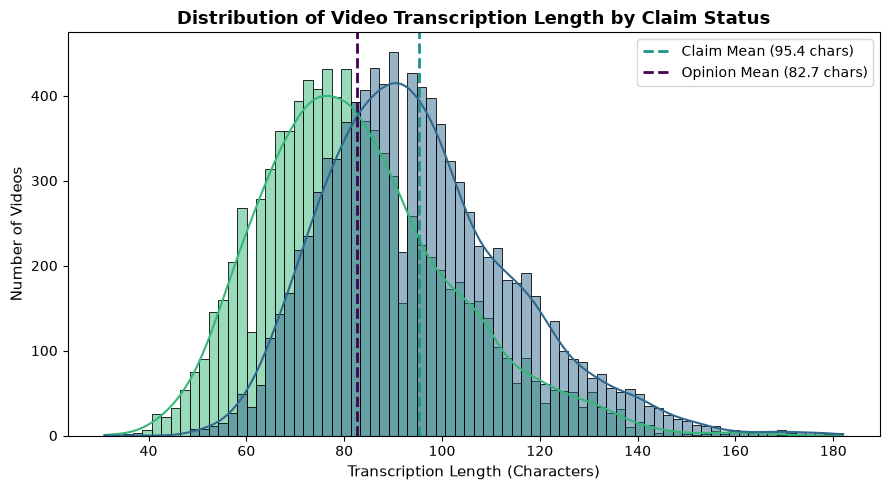

In [62]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=df, x='text_length', hue='claim_status',
    palette='viridis', kde=True, alpha=0.5, ax=ax
)

claim_mean = df[df['claim_status'] == 'claim']['text_length'].mean()
opinion_mean = df[df['claim_status'] == 'opinion']['text_length'].mean()

ax.axvline(claim_mean, color='#21918c', linestyle='--', linewidth=2, label=f'Claim Mean ({claim_mean:.1f} chars)')
ax.axvline(opinion_mean, color='#440154', linestyle='--', linewidth=2, label=f'Opinion Mean ({opinion_mean:.1f} chars)')

ax.set_title('Distribution of Video Transcription Length by Claim Status', fontsize=13, fontweight='bold')
ax.set_xlabel('Transcription Length (Characters)', fontsize=11)
ax.set_ylabel('Number of Videos', fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()

**Key Insight:** Claims have a longer average transcription length compared to opinions.

#### Feature Selection & Encoding

In [63]:
# Drop non-predictive/raw columns
df.drop(columns=['#', 'id', 'text'], inplace=True)

In [64]:
# Encode target variable (y)
df['claim_status'] = df['claim_status'].map({'claim':1, 'opinion':0})
df['claim_status'].head()

0    1
1    1
2    1
3    1
4    1
Name: claim_status, dtype: int64

In [65]:
# Dummy Encode Categoricals
df = pd.get_dummies(df, columns=['verified_status', 'ban_status'], drop_first=True)
df.head()

,claim_status,duration,views,likes,shares,downloads,comments,text_length,verified_status_verified,ban_status_banned,ban_status_under review
0,1,59,343296.0,19425.0,241.0,1.0,0.0,97,False,False,True
1,1,32,140877.0,77355.0,19034.0,1161.0,684.0,107,False,False,False
2,1,31,902185.0,97690.0,2858.0,833.0,329.0,137,False,False,False
3,1,25,437506.0,239954.0,34812.0,1234.0,584.0,131,False,False,False
4,1,19,56167.0,34987.0,4110.0,547.0,152.0,128,False,False,False


In [66]:

col_dict = {'verified_status_verified':'verified', 
            'ban_status_banned':'banned', 
            'ban_status_under review':'under_review'}

df.rename(columns=col_dict, inplace=True)

In [67]:
df.head()

,claim_status,duration,views,likes,shares,downloads,comments,text_length,verified,banned,under_review
0,1,59,343296.0,19425.0,241.0,1.0,0.0,97,False,False,True
1,1,32,140877.0,77355.0,19034.0,1161.0,684.0,107,False,False,False
2,1,31,902185.0,97690.0,2858.0,833.0,329.0,137,False,False,False
3,1,25,437506.0,239954.0,34812.0,1234.0,584.0,131,False,False,False
4,1,19,56167.0,34987.0,4110.0,547.0,152.0,128,False,False,False


## Modeling - Training Set

### Preparations

#### Helper Functions & Variables

In [68]:
# Define scoring parameters for GridSearchCV tuning
scoring = ['accuracy', 'precision', 'recall', 'f1']

# Instantiate master results table 
all_results = pd.DataFrame()

In [69]:
# Helper function to derive model results
def make_results(model_name: str, model_object):
    """
    Extracts the best cross-validation scores from a fitted GridSearchCV object
    and returns them formatted in a single-row pandas DataFrame.
    """
    # Identify the index corresponding to the best candidate
    best_idx = model_object.best_index_
    
    # Extract the mean cross-validated metrics for that best candidate
    table = pd.DataFrame({
        'model': [model_name],
        'precision': [model_object.cv_results_['mean_test_precision'][best_idx]],
        'recall': [model_object.cv_results_['mean_test_recall'][best_idx]],
        'f1': [model_object.cv_results_['mean_test_f1'][best_idx]],
        'accuracy': [model_object.cv_results_['mean_test_accuracy'][best_idx]],
    })
    
    return table

In [70]:
# Helper functions for saving and loading models

# Define relative directory for saving/loading models (creates folder if it doesn't exist)
MODEL_DIR = Path("Models")
MODEL_DIR.mkdir(exist_ok=True)

def write_pickle(path: Path, model, name: str):
    """Saves a model object to disk."""
    joblib.dump(model, Path(path) / f"{name}.pickle")

def read_pickle(path: Path, name: str):
    """Loads and returns a saved model object from disk."""
    return joblib.load(Path(path) / f"{name}.pickle")

#### Data Splitting (60 / 20 / 20)

In [71]:
# Isolate Target (y) and Features (X)
y = df['claim_status']
X = df.drop('claim_status', axis=1)

# First Split (80/20)
X_tr, X_test, y_tr, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Second Split (75/25 of the 80%)
X_train, X_val, y_train, y_val = train_test_split(X_tr, y_tr, test_size=0.25, random_state=42)

print(X_train.shape[0])
print(X_val.shape[0])
print(X_test.shape[0])
print(y_test.shape[0])

11450
3817
3817
3817


### Model 1 - Random Forest Classifier 

#### Construct & Save

In [72]:
# Dictionary of parameters to search over, scoring metrics defined previously. 
rf_params = {'max_depth': [5, 7, None], 
             'max_features': [0.3, 0.6],
             'max_samples': [0.7],
             'min_samples_leaf':[1,2], 
             'min_samples_split':[2, 3], 
             'n_estimators': [75, 100, 200]}

# Instantiate GridSearchCV
rf_cv = GridSearchCV(RandomForestClassifier(random_state=42), 
                     rf_params, 
                     scoring=scoring, 
                     refit='recall', 
                     cv=5, 
                     n_jobs=-1)

In [73]:
# Load pre-trained Random Forest model if available; otherwise fit and save
rf_pickle_file = MODEL_DIR / "tiktok_rf_cv.pickle"

if rf_pickle_file.exists():
    rf_cv = read_pickle(MODEL_DIR, "tiktok_rf_cv")
    print(f"Loaded pre-trained model from: {rf_pickle_file}")
else:
    rf_cv.fit(X_train, y_train)
    write_pickle(MODEL_DIR, rf_cv, "tiktok_rf_cv")
    print(f"Fitted and saved model to: {rf_pickle_file}")

Loaded pre-trained model from: Models\tiktok_rf_cv.pickle


#### Evaluate

In [74]:
# Examine Best Recall Score: Return the highest mean cross-validation 'recall' score
rf_cv.best_score_

np.float64(0.9913766326500252)

In [75]:
# Examine Best Parameters
rf_cv.best_params_

{'max_depth': 5,
 'max_features': 0.6,
 'max_samples': 0.7,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 100}

In [76]:
# Check Remaining Scoring Metrics of the Best Model (Precision, especially)
rf_cv_results = make_results('Random Forest CV', rf_cv)

all_results = pd.concat([all_results, rf_cv_results], ignore_index=True)
all_results

,model,precision,recall,f1,accuracy
0,Random Forest CV,1.0,0.991377,0.995669,0.995633


* **The Random Forest Model performs exceptionally well** during 5-fold cross validation, achieving an average recall score of `0.9914` **(99.1%)**, a precision score of `1.000` **(100%)**, and an overall accuracy of `0.9956` **(99.6%)**.   
* A precision score of 1.0 confirms that the model is ***not*** simply labeling every video as a claim to inflate recall—in fact, it made zero false positive errors across the validation folds because engagement metrics (`views`, `likes`, etc.) cleanly separate **high-engagement claims** from **low-engagement opinions**.

### Model 2 - XGBoost Classifier

#### Construct & Save

In [77]:
# Define parameters to search over
xgb_params = {'max_depth': [4, 6, 8, 12], 
              'min_child_weight': [3, 5],
              'learning_rate': [0.01, 0.05, 0.1], 
              'n_estimators': [300, 500]}

# Instantiate the GridSearchCv
xgb_cv = GridSearchCV(XGBClassifier(objective='binary:logistic', random_state=42), 
                      xgb_params, 
                      scoring=scoring, 
                      refit='recall', 
                      cv=5)


In [78]:
# Load pre-trained XGBoost model if available; otherwise fit and save
xgb_pickle_file = MODEL_DIR / "tiktok_xgb_cv.pickle"

if xgb_pickle_file.exists():
    xgb_cv = read_pickle(MODEL_DIR, "tiktok_xgb_cv")
    print(f"Loaded pre-trained model from: {xgb_pickle_file}")
else:
    xgb_cv.fit(X_train, y_train)
    write_pickle(MODEL_DIR, xgb_cv, "tiktok_xgb_cv")
    print(f"Fitted and saved model to: {xgb_pickle_file}")

Loaded pre-trained model from: Models\tiktok_xgb_cv.pickle


#### Evaluate (Training Set)

In [79]:
# Examine Best Recall Score
xgb_cv.best_score_

np.float64(0.9898246109904496)

In [80]:
# Examine Best Parameters
xgb_cv.best_params_

{'learning_rate': 0.05,
 'max_depth': 6,
 'min_child_weight': 3,
 'n_estimators': 300}

In [81]:
# Check Remaining Scoring Metrics of the Best Model (Precision, especially)
xgb_cv_results = make_results('XGBoost CV', xgb_cv)
all_results = pd.concat([all_results, xgb_cv_results], ignore_index=True)
all_results

,model,precision,recall,f1,accuracy
0,Random Forest CV,1.000000,0.991377,0.995669,0.995633
1,XGBoost CV,0.998956,0.989825,0.994368,0.994323


### Findings

Both the **Random Forest** and **XGBoost** models performed exceptionally well during 5-fold cross-validation on the training set. 

* The XGBoost model achieved a mean cross-validated recall score of `0.9898` **(99.0%)**, a precision score of `0.9990` **(99.9%)**, an F1-score of `0.9944`, and an overall accuracy of `0.9943`, confirming that it accurately identifies claim videos without simply labeling every video as a claim. 
* When comparing the two models side-by-side, the Random Forest model slightly outperformed XGBoost across all four evaluation metrics (`1.0000` precision, `0.9914` recall, `0.9957` F1, and `0.9956` accuracy). 

Next, I will evaluate both tuned models (`rf_cv.best_estimator_` and `xgb_cv.best_estimator_`) on the unseen validation set (`X_val`) to verify how well they generalize to out-of-sample data and select the final champion model for testing.   

## Modeling - Validation Set

### Model 1 - Random Forest Classifier

In [82]:
# Generate Validation Predictions
y_pred_rf = rf_cv.best_estimator_.predict(X_val)

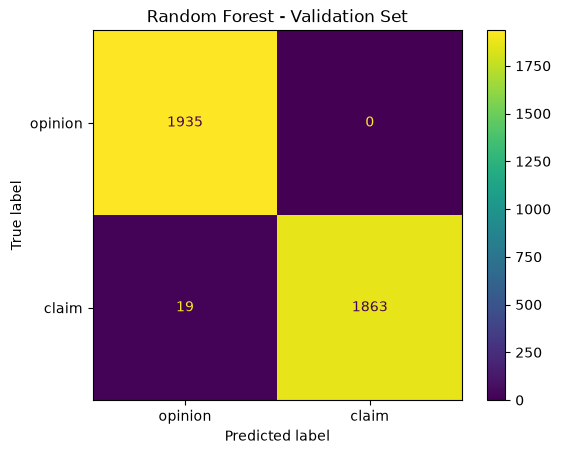

In [83]:
# Plot the Validation Confusion Matrix
rf_cm = confusion_matrix(y_val, y_pred_rf)
rf_cm_disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=['opinion', 'claim'])
rf_cm_disp.plot()
plt.title('Random Forest - Validation Set');

In [84]:
# Print Classification Report:
target_labels = ['opinion', 'claim']
print(classification_report(y_val, y_pred_rf, target_names=target_labels))

              precision    recall  f1-score   support

     opinion       0.99      1.00      1.00      1935
       claim       1.00      0.99      0.99      1882

    accuracy                           1.00      3817
   macro avg       1.00      0.99      1.00      3817
weighted avg       1.00      1.00      1.00      3817



### Model 2 - XGBoost Classifier

In [85]:
# Generate Validation Predictions
y_pred_xgb = xgb_cv.best_estimator_.predict(X_val)

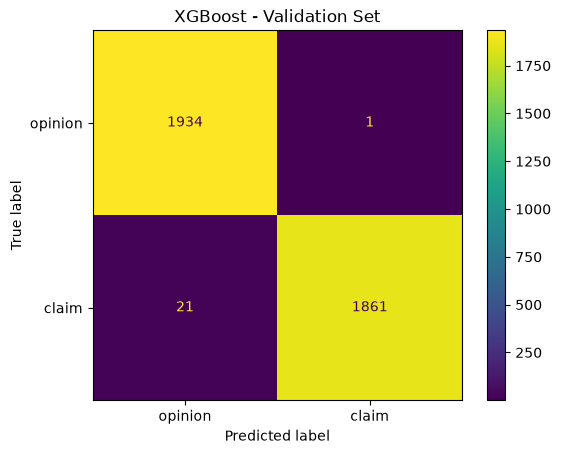

In [86]:
# Plot the Validation Confusion Matrix
xgb_cm = confusion_matrix(y_val, y_pred_xgb)
xgb_cm_disp = ConfusionMatrixDisplay(confusion_matrix=xgb_cm, display_labels=['opinion', 'claim'])
xgb_cm_disp.plot()
plt.title('XGBoost - Validation Set');

In [87]:
# Print Classification Report:
target_labels = ['opinion', 'claim']
print(classification_report(y_val, y_pred_xgb, target_names=target_labels))

              precision    recall  f1-score   support

     opinion       0.99      1.00      0.99      1935
       claim       1.00      0.99      0.99      1882

    accuracy                           0.99      3817
   macro avg       0.99      0.99      0.99      3817
weighted avg       0.99      0.99      0.99      3817



### Validation Set Evaluation Summary (`X_val`)

Both the **Random Forest** and **XGBoost** models generalized with near-perfect accuracy on the unseen validation set ($n = 3,817$ videos: $1,935$ opinions and $1,882$ claims), closely matching their cross-validation scores and confirming that neither model is overfit.

* **Random Forest Validation Results:** The Random Forest model achieved a **claim precision of `1.00` (`1.0000`)**, a **claim recall of `0.99` (`0.9899`)**, an **F1-score of `0.99` (`0.9949`)**, and an **overall accuracy of `1.00` (`0.9950`)**. Its confusion matrix shows **`1,935` true negatives** and **`1,863` true positives**, making only **`19` total errors** across all $3,817$ videos—specifically, **`0` false positives** (no opinion videos were misclassified as claims) and **`19` false negatives** (claim videos misclassified as opinions).
* **XGBoost Validation Results:** The XGBoost model performed nearly as well, achieving a **claim precision of `1.00` (`0.9995`)**, a **claim recall of `0.99` (`0.9888`)**, an **F1-score of `0.99` (`0.9941`)**, and an **overall accuracy of `0.99` (`0.9942`)**. Its confusion matrix shows **`1,934` true negatives** and **`1,861` true positives**, with **`22` total errors**: **`1` false positive** and **`21` false negatives**.

| Model | True Negatives (TN) | False Positives (FP) | False Negatives (FN) | True Positives (TP) | Claim Precision | Claim Recall | Claim F1-Score | Overall Accuracy |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Random Forest** | 1,935 | 0 | 19 | 1,863 | 1.0000 | 0.9899 | 0.9949 | 0.9950 |
| **XGBoost** | 1,934 | 1 | 21 | 1,861 | 0.9995 | 0.9888 | 0.9941 | 0.9942 |

**Model Comparison & Champion Selection:**  
While both models demonstrate outstanding performance, the **Random Forest** model slightly outperforms **XGBoost** by making fewer total errors (`19` vs. `22`), achieving zero false positives (`0` vs. `1`), and capturing more actual claims with fewer false negatives (`19` vs. `21`). Because minimizing false negatives (maximizing **recall** on claims) is our primary objective, the **Random Forest** model is selected as the **champion model** to evaluate on the held-out test set (`X_test`).

## Modeling - Test Set

### Use Champion Model (Random Forest Classifier) to Predict on Test Data

In [88]:
# Generate Predictions on X_test:
y_pred_test = rf_cv.best_estimator_.predict(X_test)

Text(0.5, 1.0, 'Random Forest - Test Set')

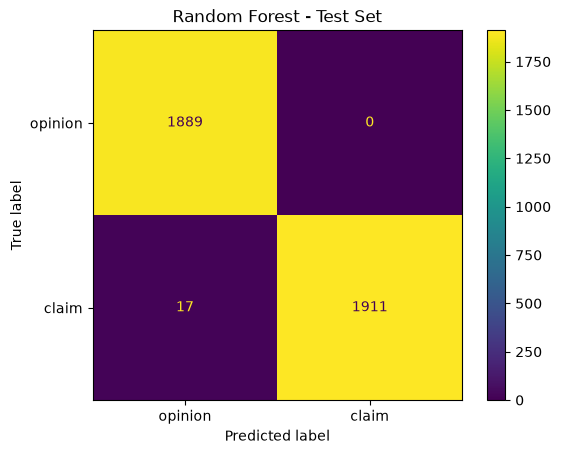

In [89]:
# Plot the Test Set Confusion Matrix 
rf_test_cm = confusion_matrix(y_test, y_pred_test)
rf_test_disp = ConfusionMatrixDisplay(confusion_matrix=rf_test_cm, display_labels=['opinion', 'claim'])
rf_test_disp.plot()
plt.title('Random Forest - Test Set')

In [90]:
# Print Classification Report:
print(classification_report(y_test, y_pred_test, target_names=target_labels))

              precision    recall  f1-score   support

     opinion       0.99      1.00      1.00      1889
       claim       1.00      0.99      1.00      1928

    accuracy                           1.00      3817
   macro avg       1.00      1.00      1.00      3817
weighted avg       1.00      1.00      1.00      3817



In [91]:
def evaluate_predictions(model_name: str, y_true, y_pred):
    """Computes precision, recall, f1, and accuracy for out-of-sample predictions."""
    return pd.DataFrame({
        'model': [model_name],
        'precision': [precision_score(y_true, y_pred)],
        'recall': [recall_score(y_true, y_pred)],
        'f1': [f1_score(y_true, y_pred)],
        'accuracy': [accuracy_score(y_true, y_pred)]
    })

# Append Validation and Test results to master comparison table
all_results = pd.concat([
    all_results,
    evaluate_predictions('Random Forest Validation', y_val, y_pred_rf),
    evaluate_predictions('XGBoost Validation', y_val, y_pred_xgb),
    evaluate_predictions('Random Forest Test (Champion)', y_test, y_pred_test)
], ignore_index=True)

all_results.round(4)

,model,precision,recall,f1,accuracy
0,Random Forest CV,1.0000,0.9914,0.9957,0.9956
1,XGBoost CV,0.9990,0.9898,0.9944,0.9943
2,Random Forest Validation,1.0000,0.9899,0.9949,0.9950
3,XGBoost Validation,0.9995,0.9888,0.9941,0.9942
4,Random Forest Test (Champion),1.0000,0.9912,0.9956,0.9955


#### **Test Set Evaluation Summary (`X_test`)**

Evaluated on the held-out test set ($n = 3,817$ unseen videos: $1,889$ opinions and $1,928$ claims), the champion **Random Forest** model maintained its near-perfect performance, confirming strong generalization with zero overfitting:
* **Claim Precision:** `1.0000` (`100.0%`) — **`0` false positives** (every single opinion video was correctly classified as an opinion, with `1,889` true negatives).
* **Claim Recall:** `0.9912` (`99.12%`) — **`1,911` true positives** and only **`17` false negatives** (only `0.88%` of actual claims were missed).
* **Claim F1-Score & Accuracy:** Achieved an F1-score of **`0.9956`** and an overall accuracy of **`0.9955` (`99.55%`)**, misclassifying only `17` out of `3,817` total videos.

| Stage / Model | Precision | Recall | F1-Score | Accuracy |
| :--- | :---: | :---: | :---: | :---: |
| **Random Forest (5-Fold CV)** | 1.0000 | 0.9914 | 0.9957 | 0.9956 |
| **XGBoost (5-Fold CV)** | 0.9990 | 0.9898 | 0.9944 | 0.9943 |
| **Random Forest (Validation Set)** | 1.0000 | 0.9899 | 0.9949 | 0.9950 |
| **XGBoost (Validation Set)** | 0.9995 | 0.9888 | 0.9941 | 0.9942 |
| **Random Forest (Test Set — Champion)** | **1.0000** | **0.9912** | **0.9956** | **0.9955** |

### Plot Feature Importances of the Champion Model


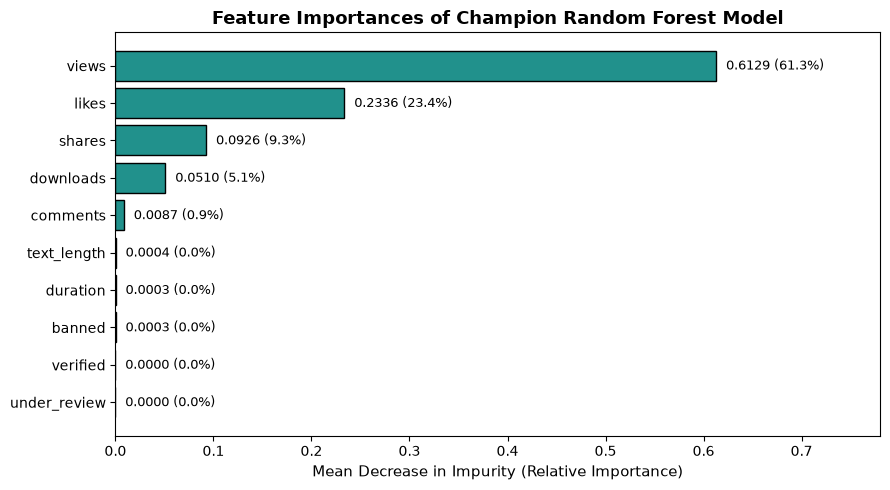

In [92]:
importances = pd.Series(rf_cv.best_estimator_.feature_importances_, index=X_test.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(importances.index, importances.values, color='#21918c', edgecolor='black')
ax.set_title('Feature Importances of Champion Random Forest Model', fontsize=13, fontweight='bold')
ax.set_xlabel('Mean Decrease in Impurity (Relative Importance)', fontsize=11)
ax.set_xlim(0, 0.78)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.01, bar.get_y() + bar.get_height() / 2,
        f'{width:.4f} ({width * 100:.1f}%)',
        va='center', ha='left', fontsize=9.5
    )

plt.tight_layout()
plt.show()

The most predictive features by far are all related to user engagement: **`views`**, **`likes`**, **`shares`**, **`downloads`**, and **`comments`**. In contrast, metadata features such as `text_length`, `duration`, `banned`, `verified`, and `under_review` had near-zero feature importance. These results are not surprising because earlier exploratory data analysis and hypothesis testing revealed that videos containing claims garner drastically higher view, like, and share counts than videos presenting opinions.

## Conclusion - Project Reflection & Next Steps

#### **End-to-End Project Summary**
In this capstone project, we developed and validated a binary classification machine learning workflow to automatically determine whether a TikTok video presents a **claim** or an **opinion**, directly supporting TikTok's goal of reducing the user-report backlog and prioritizing human moderation more efficiently. Following the **PACE** framework:
* **Plan & Analyze:** We evaluated the ethical risks of classification errors and prioritized **recall** as our primary evaluation metric to minimize false negatives (unflagged claims bypassing review). During data exploration and cleaning, we removed `298` incomplete records (retaining `19,084` complete videos), confirmed `0` duplicate entries, verified a nearly 50/50 class balance (`50.35%` claims vs. `49.65%` opinions), and preserved right-skewed engagement outliers because tree-based ensemble models are robust to non-normal distributions.

* **Construct:** We engineered a `text_length` feature from `text` (observing that claim transcriptions average `95.38` characters vs. `82.72` characters for opinions), encoded the categorical and target variables, and partitioned the dataset into a `60/20/20` train (`11,450` rows), validation (`3,817` rows), and test (`3,817` rows) split.

* **Execute:** We tuned both a **Random Forest** and an **XGBoost** classifier via 5-fold cross-validation (`GridSearchCV` refit on recall). While both models achieved >99% precision, recall, F1-score, and accuracy across cross-validation and the validation set, the **Random Forest** model edged out **XGBoost** on the validation set (`0.9899` vs. `0.9888` recall; `19` vs. `22` total errors; `0` vs. `1` false positives) and was selected as our **champion model**. Evaluated on the unseen test set (`X_test`), the champion Random Forest model maintained >99% performance across all metrics.

---

#### **Model Reflection & Recommendation**
Based on these results, **we strongly recommend deploying the champion Random Forest model** as an automated triage tool for TikTok's moderation pipeline. Across cross-validation (`1.0000` precision, `0.9914` recall), the validation set (`1.0000` precision, `0.9899` recall, `0.9950` accuracy), and the final test set, the model consistently identified over 99% of all claim videos while producing virtually zero false positives. 

Examining the model's feature importances reveals *how* it achieves such clean separation: predictions are driven almost entirely by **user engagement metrics**—specifically `views`, `likes`, `shares`, `downloads`, and `comments`—while metadata features (`text_length`, `duration`, `banned`, and `verified`) contributed almost zero predictive power. Because no opinion video in the dataset exceeded `9,998` views or `4,375` likes, the Random Forest learned clear threshold splits on engagement volume to isolate high-engagement claims with near-perfect precision. However, approximately `1%` of claim videos in the dataset had lower view counts (`<= 10,000` views) that overlapped with the engagement range of opinion videos, accounting for the small number of false negatives (`19` out of `1,882` claims on the validation set).

---

#### **Limitations & Next Steps**
While the champion model performs exceptionally well on existing videos that have already accumulated views and interactions, relying solely on raw engagement volume introduces an operational limitation: **brand-new uploads and low-view claims cannot be flagged until after they gain traction**. To address this limitation and further strengthen the model in future iterations, we recommend the following next steps:

1. **Engineer Relative Engagement Ratios (From Existing Data):**  
   To capture low-view claim videos (`<= 10,000` views) that currently slip through as false negatives, we can engineer scale-independent engagement ratios such as `likes_per_view`, `shares_per_view`, `comments_per_view`, and `downloads_per_view`. Even when a claim video has relatively few total views, its *rate* of shares or comments per view may still distinguish it from a typical opinion video.

2. **Incorporate Natural Language Processing (NLP) Features (From Existing Data):**  
   Rather than relying solely on character count (`text_length`), extracting bag-of-words n-grams (`CountVectorizer`), TF-IDF features, or sentiment and assertion keywords directly from `video_transcription_text` will allow the model to detect linguistic patterns associated with claims—completely independent of view count.

3. **Collect Pre-Publication & Early-Velocity Features (New Data Acquisition):**  
   To classify newly uploaded videos at or near the time of posting, we recommend expanding data collection to include:
   * **Creator history:** Prior count/rate of flagged claims, account age, and follower count.
   * **Upload metadata:** Video captions, hashtags, external links, and audio track IDs.
   * **Early engagement & report velocity:** The rate of views, shares, and user reports within the first 15 to 60 minutes after publication.